## Task 1

In [2]:
import re
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

SAMPLE_REVIEWS = [
    "Good service and fast delivery. The price is great, worth every penny!",
    "Great product, good quality. Delivery was fast and the service was perfect.",
    "The price is too high for this quality. Not worth the cost.",
    "Bad service, slow delivery. I am not happy with the support.",
    "Nice product, good price. Great value for the money.",
    "Delivery was late and the package was damaged. Poor service.",
    "Excellent quality and perfect packaging. Fast delivery, great service!",
    "The cost is reasonable, good value. I love the quality of this product.",
    "Terrible support, nobody answered. Bad experience, slow service.",
    "Good product but the delivery took too long. Service could be better.",
    "Cheap price and nice quality. Worth buying, great deal.",
    "The package arrived damaged. Poor quality and bad packaging.",
    "Fast shipping, great packaging, perfect product. Highly recommend!",
    "Support was helpful and friendly. Great service, good experience.",
    "Too expensive, the price is not worth it. Quality is average.",
    "Amazing value for the price. Nice quality, fast delivery.",
    "Slow shipping and bad support. I will not buy again.",
    "Friendly staff, helpful support, great service. Good experience overall.",
    "The product is good, the price is fair. Delivery was fast.",
    "Poor quality, expensive price. Very bad experience with the delivery.",
    "Perfect quality, fast shipping. Great product and nice packaging.",
    "Helpful support and fast service. I love this product, great value.",
    "Delivery was slow, the package was late. Bad service, poor support.",
    "Good price, good quality, fast delivery. Great experience!",
    "Not happy, the product is damaged. Bad quality and expensive cost.",
    "Great deal, cheap price and worth the money. Nice product.",
    "Friendly and helpful service. Support answered fast, great experience.",
    "Late delivery, damaged package, poor packaging. Not recommend.",
    "Excellent product, perfect price, fast shipping. Love it!",
    "Quality is nice but the price is high. Delivery was good.",
]

texts = SAMPLE_REVIEWS
print(f"Відгуків: {len(texts)}")

Відгуків: 30


In [3]:
FALLBACK_STOPWORDS = set("""a an the and or but if is are was were be been am i me my we our you your he she it its
they them their this that these those of to in on at for with from by as so than too very can will just not no
do does did have has had would could should about into over under again then there here what which who whom
when where why how all any both each few more most other some such only own same s t""".split())

def get_stopwords():
    try:
        import nltk
        from nltk.corpus import stopwords
        try:
            return set(stopwords.words("english"))
        except LookupError:
            nltk.download("stopwords", quiet=True)
            return set(stopwords.words("english"))
    except Exception:
        return FALLBACK_STOPWORDS

stop = get_stopwords()
print("Стоп-слів:", len(stop))

Стоп-слів: 198


In [4]:
def split_sentences(text):
    """Ділимо відгук на речення за . ! ?"""
    return [s for s in re.split(r"[.!?]+", text) if s.strip()]

def clean(sentence):
    """Нижній регістр + прибираємо пунктуацію й цифри."""
    return re.sub(r"[^a-z\s]", " ", sentence.lower())

sentences = []
for review in texts:
    for sent in split_sentences(review):
        tokens = [t for t in clean(sent).split() if t not in stop and len(t) > 1]
        if tokens:
            sentences.append(tokens)

with open("sentences.pkl", "wb") as f:
    pickle.dump(sentences, f)

print(f"Отримано {len(sentences)} речень. Приклади:")
for s in sentences:
    print("  ", s)

Отримано 60 речень. Приклади:
   ['good', 'service', 'fast', 'delivery']
   ['price', 'great', 'worth', 'every', 'penny']
   ['great', 'product', 'good', 'quality']
   ['delivery', 'fast', 'service', 'perfect']
   ['price', 'high', 'quality']
   ['worth', 'cost']
   ['bad', 'service', 'slow', 'delivery']
   ['happy', 'support']
   ['nice', 'product', 'good', 'price']
   ['great', 'value', 'money']
   ['delivery', 'late', 'package', 'damaged']
   ['poor', 'service']
   ['excellent', 'quality', 'perfect', 'packaging']
   ['fast', 'delivery', 'great', 'service']
   ['cost', 'reasonable', 'good', 'value']
   ['love', 'quality', 'product']
   ['terrible', 'support', 'nobody', 'answered']
   ['bad', 'experience', 'slow', 'service']
   ['good', 'product', 'delivery', 'took', 'long']
   ['service', 'could', 'better']
   ['cheap', 'price', 'nice', 'quality']
   ['worth', 'buying', 'great', 'deal']
   ['package', 'arrived', 'damaged']
   ['poor', 'quality', 'bad', 'packaging']
   ['fast', 'shipp

Task2

In [6]:
model = Word2Vec(sentences, vector_size=100, window=5, min_count=2, sg=1,
                 workers=1, seed=42, epochs=100)
model.save("word2vec.model")
print(f"Розмір словника: {len(model.wv)} слів")

Розмір словника: 35 слів


In [7]:
preferred = ["good", "service", "price", "delivery", "quality",
             "support", "product", "fast", "package", "experience"]
keywords = [w for w in preferred if w in model.wv]
for w in model.wv.index_to_key:          # відсортовано за частотою
    if len(keywords) >= 10:
        break
    if w not in keywords:
        keywords.append(w)
keywords = keywords[:10]

rows = []
for w in keywords:
    sims = model.wv.most_similar(w, topn=5)
    rows.append({
        "Ключове слово": w,
        "Близькі слова": ", ".join(s[0] for s in sims),
        "Косинусна схожість": ", ".join(f"{s[1]:.2f}" for s in sims),
    })

similar_df = pd.DataFrame(rows)
similar_df.to_csv("similar_words.csv", index=False, encoding="utf-8-sig")
similar_df

,Ключове слово,Близькі слова,Косинусна схожість
0,good,"late, price, fast, quality, great","0.39, 0.38, 0.36, 0.36, 0.32"
1,service,"cost, price, quality, great, late","0.37, 0.34, 0.34, 0.33, 0.29"
2,price,"quality, great, delivery, late, support","0.49, 0.44, 0.42, 0.39, 0.38"
3,delivery,"support, quality, price, great, damaged","0.45, 0.45, 0.42, 0.41, 0.40"
4,quality,"great, support, shipping, price, perfect","0.58, 0.55, 0.54, 0.49, 0.48"
5,support,"quality, great, shipping, delivery, price","0.55, 0.52, 0.49, 0.45, 0.38"
6,product,"quality, love, bad, perfect, support","0.42, 0.37, 0.36, 0.33, 0.33"
7,fast,"experience, quality, great, poor, value","0.44, 0.40, 0.39, 0.39, 0.38"
8,package,"perfect, quality, packaging, late, fast","0.46, 0.43, 0.39, 0.36, 0.35"
9,experience,"fast, great, price, support, good","0.44, 0.36, 0.33, 0.32, 0.31"


Task3

In [8]:
words = model.wv.index_to_key
vectors = model.wv.vectors

N_CLUSTERS = 5
kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=42)
labels = kmeans.fit_predict(vectors)

clusters_df = pd.DataFrame({"word": words, "cluster": labels})
clusters_df.to_csv("word_clusters.csv", index=False, encoding="utf-8-sig")

for c in range(N_CLUSTERS):
    idx = np.where(labels == c)[0]
    dist = np.linalg.norm(vectors[idx] - kmeans.cluster_centers_[c], axis=1)
    top = idx[np.argsort(dist)[:10]]
    print(f"Кластер {c} ({len(idx)} слів): " + ", ".join(words[i] for i in top))

Кластер 0 (6 слів): fast, poor, experience, good, package, cost
Кластер 1 (9 слів): slow, bad, value, excellent, late, worth, deal, packaging, service
Кластер 2 (8 слів): delivery, quality, great, shipping, support, damaged, perfect, price
Кластер 3 (5 слів): cheap, nice, high, expensive, friendly
Кластер 4 (7 слів): love, answered, happy, money, helpful, recommend, product


Task4

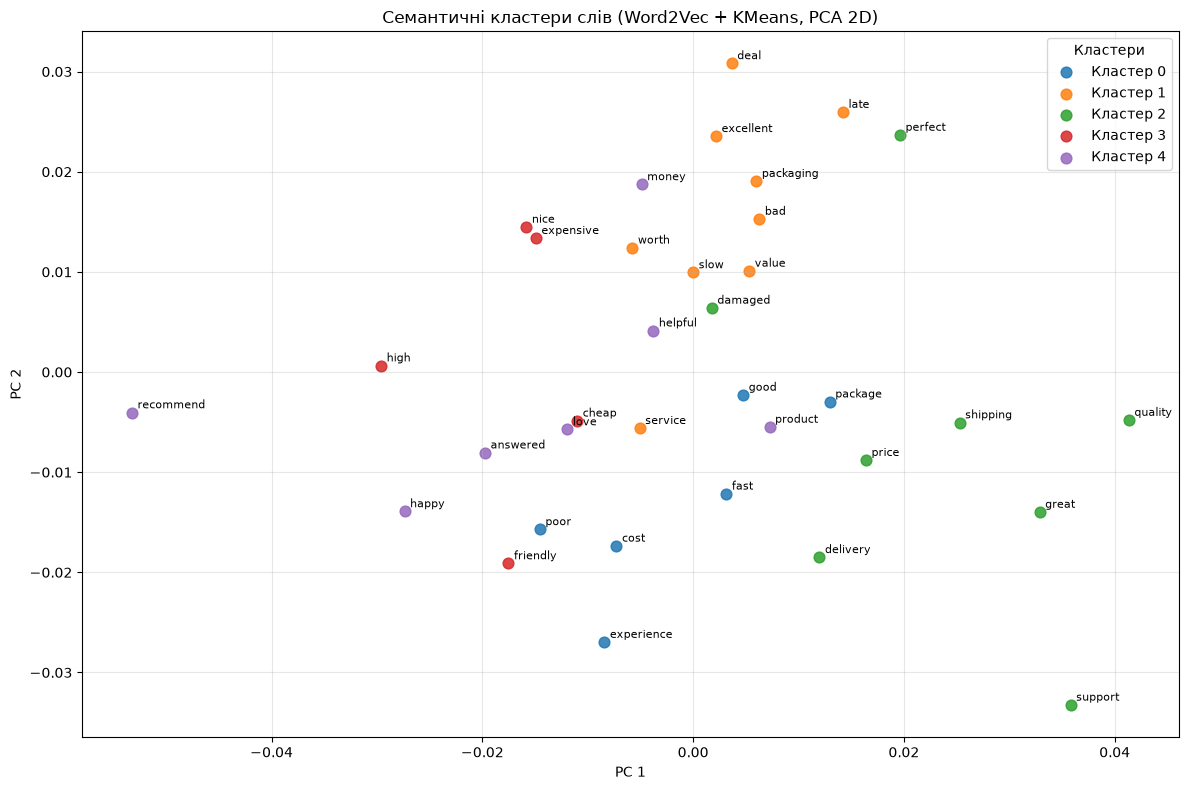

In [9]:
coords = PCA(n_components=2, random_state=42).fit_transform(vectors)
plot_df = pd.DataFrame({"word": words, "cluster": labels,
                        "x": coords[:, 0], "y": coords[:, 1]})

fig, ax = plt.subplots(figsize=(12, 8))
cmap = plt.get_cmap("tab10")
for c in range(N_CLUSTERS):
    part = plot_df[plot_df["cluster"] == c]
    ax.scatter(part["x"], part["y"], s=60, color=cmap(c), label=f"Кластер {c}", alpha=0.85)
    for _, r in part.iterrows():
        ax.annotate(r["word"], (r["x"], r["y"]), fontsize=8,
                    xytext=(4, 3), textcoords="offset points")

ax.set_title("Семантичні кластери слів (Word2Vec + KMeans, PCA 2D)")
ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")
ax.legend(title="Кластери")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("semantic_clusters.png", dpi=150)
plt.show()